In [153]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import umap.umap_ as umap
import seaborn as sns
import joblib
from gene_thesaurus import GeneThesaurus
from dotenv import load_dotenv

load_dotenv()

X_labeled_diagnostic_csv_path = os.getenv('X_LABELED_DIAGNOSTIC_CSV_PATH')
y_labeled_diagnostic_tsv_path = os.getenv('Y_LABELED_DIAGNOSTIC_TSV_PATH')
color_palette_tsv_path = os.getenv('COLOR_PALETTE_TSV_PATH')
output_dir = os.getenv('OUTPUT_DIR')
n_jobs = int(os.getenv('N_JOBS', 1))
random_seed = int(os.getenv('RANDOM_SEED', 42))
selected_features_path = os.path.join(output_dir, "selected_features.pkl")
rf_model_path = os.getenv('RF_MODEL_PATH')
N_TOP_FEATURES = 500

print("Configuration:")
print(f"X_labeled_diagnostic_csv_path: {X_labeled_diagnostic_csv_path}")
print(f"y_labeled_diagnostic_tsv_path: {y_labeled_diagnostic_tsv_path}")
print(f"color_palette_tsv_path: {color_palette_tsv_path}")
print(f"output_dir: {output_dir}")
print(f"n_jobs: {n_jobs}")
print(f"random_seed: {random_seed}")
print(f"selected_features_path: {selected_features_path}")
print(f"rf_model_path: {rf_model_path}")
print(f"N_TOP_FEATURES: {N_TOP_FEATURES}")


Configuration:
X_labeled_diagnostic_csv_path: /home/mariya/Data/pallas/nf-core-gexml-output-labeled-diagnostic/transpose/transposed.csv
y_labeled_diagnostic_tsv_path: /home/mariya/Data/pallas/nf-core-gexml-output-labeled-diagnostic/class/subtypes.tsv
color_palette_tsv_path: /home/mariya/Data/pallas/colors.tsv
output_dir: /home/mariya/Data/pallas/training
n_jobs: 10
random_seed: 42
selected_features_path: /home/mariya/Data/pallas/training/selected_features.pkl
rf_model_path: /home/mariya/Data/pallas/training/final_model.pkl
N_TOP_FEATURES: 500


In [154]:
# Load selected features
selected_features = joblib.load(selected_features_path)
selected_features

Index(['ENSG00000000938', 'ENSG00000001036', 'ENSG00000001561',
       'ENSG00000001617', 'ENSG00000002586', 'ENSG00000002587',
       'ENSG00000002745', 'ENSG00000002746', 'ENSG00000003096',
       'ENSG00000003147',
       ...
       'ENSG00000284690', 'ENSG00000284713', 'ENSG00000284730',
       'ENSG00000284770', 'ENSG00000288649', 'ENSG00000288658',
       'ENSG00000288701', 'ENSG00000288722', 'ENSG00000290292',
       'ENSG00000291237'],
      dtype='object', length=3931)

In [155]:
# Load model
rf_model = joblib.load(rf_model_path)
rf_model.feature_importances_

array([6.44656900e-05, 3.82781583e-04, 9.11475563e-05, ...,
       3.53229726e-06, 4.62253499e-06, 5.73833850e-06], shape=(3931,))

In [156]:
# Join selected features and feature importances
feature_importances = pd.DataFrame({
    "feature": selected_features,
    "importance": rf_model.feature_importances_
})
feature_importances_ranked = feature_importances.sort_values(by="importance", ascending=False)
feature_importances_ranked

# Translate feature names to gene symbols
gt = GeneThesaurus(".")
translated = gt.translate_genes(feature_importances_ranked["feature"].tolist(),
                               source="ensembl_id", target="symbol")
feature_importances_ranked["gene_symbol"] = feature_importances_ranked["feature"].map(translated)
feature_importances_ranked

# Get top 100 features
top_features = feature_importances_ranked.head(N_TOP_FEATURES)
top_genes = top_features["feature"].tolist()
top_genes

['ENSG00000184507',
 'ENSG00000145794',
 'ENSG00000248329',
 'ENSG00000157985',
 'ENSG00000143995',
 'ENSG00000079102',
 'ENSG00000105642',
 'ENSG00000185630',
 'ENSG00000185046',
 'ENSG00000101115',
 'ENSG00000156298',
 'ENSG00000176595',
 'ENSG00000117519',
 'ENSG00000184185',
 'ENSG00000132932',
 'ENSG00000157680',
 'ENSG00000133392',
 'ENSG00000078399',
 'ENSG00000159147',
 'ENSG00000124788',
 'ENSG00000196208',
 'ENSG00000250366',
 'ENSG00000068383',
 'ENSG00000035720',
 'ENSG00000047644',
 'ENSG00000151502',
 'ENSG00000118946',
 'ENSG00000081189',
 'ENSG00000142188',
 'ENSG00000164330',
 'ENSG00000253293',
 'ENSG00000048052',
 'ENSG00000183196',
 'ENSG00000179241',
 'ENSG00000173482',
 'ENSG00000101197',
 'ENSG00000185917',
 'ENSG00000180592',
 'ENSG00000120093',
 'ENSG00000196092',
 'ENSG00000159267',
 'ENSG00000169752',
 'ENSG00000186187',
 'ENSG00000174233',
 'ENSG00000196730',
 'ENSG00000106006',
 'ENSG00000172889',
 'ENSG00000148655',
 'ENSG00000182742',
 'ENSG00000130653',


In [157]:

color_palette = pd.read_csv(color_palette_tsv_path, sep='\t', index_col=0, header=None).squeeze("columns").to_dict()
color_palette


{'AML, KMT2A-r': '#d70000',
 'AML, RUNX1::RUNX1T1': '#8659ff',
 'AML, NUP98-r': '#008a00',
 'AML, CBFB::MYH11': '#00aeca',
 'AML, CBFA2T3::GLIS2': '#aedb00',
 'AML, NPM1alt': '#ff7dd2',
 'AML, APL-PML::RARA': '#6d0051',
 'AML, CEBPAalt': '#ffa220',
 'AML, other': '#04009a',
 'B-ALL, PAX5alt': '#00ebbe',
 'B-ALL, PAX5 P80R': '#712400',
 'B-ALL, high hyperdiploid': '#aaa2ff',
 'B-ALL, TCF3::PBX1': '#a26900',
 'B-ALL, hypodiploid': '#0069ae',
 'B-ALL, KMT2A-r': '#ca00be',
 'B-ALL, BCR::ABL1-like': '#96a22d',
 'B-ALL, ETV6::RUNX1': '#450071',
 'B-ALL, iAMP21': '#004d00',
 'B-ALL, DUX4-r': '#e77569',
 'B-ALL, ETV6::RUNX1-like': '#00b282',
 'B-ALL, ZNF384-r': '#ef047d',
 'B-ALL, NUTM1-r': '#ffe365',
 'B-ALL, BCR::ABL1': '#a2394d',
 'B-ALL, MEF2D-r': '#ce65ff',
 'B-ALL, IKZF1 N159Y': '#4500ff',
 'B-ALL, MYC-r': '#65e7ff',
 'B-ALL, HLF-r': '#4192ff',
 'B-ALL, other': '#00c224',
 'T-ALL': '#a6ffa2',
 'Non-leukemic': '#82419e'}

In [158]:
import pandas as pd
import numpy as np
import umap
import hdbscan
from sklearn.preprocessing import OneHotEncoder

def create_umap(X, y):
    reducer = umap.UMAP(n_neighbors=15,
                    min_dist=0.1,
                    n_components=2,
                    random_state=random_seed)

    embedding_umap = reducer.fit_transform(X)

    umap_df = pd.DataFrame(embedding_umap, columns=['UMAP1', 'UMAP2'], index=X.index)
    umap_df['label'] = y.loc[umap_df.index]
    return umap_df

def show_umap(umap_df, title, palette, legend_title='Subtype'):
    # Plot UMAP
    plt.figure(figsize=(10,10))
    sns.scatterplot(x='UMAP1',
                    y='UMAP2',
                    hue='label',
                    data=umap_df,
                    palette=palette,
                    s=50,
                    alpha=0.8)

    plt.title(title, fontsize=18)
    plt.legend(
        title=legend_title,
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        borderaxespad=0,
        prop={'size': 8}
    )
    plt.tight_layout()
    plt.show()

# Create new col "disease" that sets B-ALL, T-ALL, AML or Non-leukemic
def map_disease(subtype):
    if "B-ALL" in subtype:
        return "B-ALL"
    elif "T-ALL" in subtype:
        return "T-ALL"
    elif "AML" in subtype:
        return "AML"
    else:
        return "Non-leukemic"

In [159]:
# Read in X and y
X_labeled_diagnostic = pd.read_csv(X_labeled_diagnostic_csv_path, index_col=0)
y_labeled_diagnostic = pd.read_csv(y_labeled_diagnostic_tsv_path, sep='\t', index_col=0)


In [160]:

y_labeled_diagnostic["class"].values

array(['B-ALL, ETV6::RUNX1', 'B-ALL, ETV6::RUNX1', 'B-ALL, ETV6::RUNX1',
       ..., 'B-ALL, high hyperdiploid', 'B-ALL, high hyperdiploid',
       'B-ALL, high hyperdiploid'], shape=(3237,), dtype=object)

In [161]:
# Get just selected features
X_labeled_diagnostic = X_labeled_diagnostic[top_genes]
X_labeled_diagnostic

,ENSG00000184507,ENSG00000145794,ENSG00000248329,ENSG00000157985,ENSG00000143995,ENSG00000079102,ENSG00000105642,ENSG00000185630,ENSG00000185046,ENSG00000101115,...,ENSG00000170571,ENSG00000113552,ENSG00000182175,ENSG00000142694,ENSG00000164292,ENSG00000142583,ENSG00000164161,ENSG00000198795,ENSG00000145431,ENSG00000103034
id,,,,,,,,,,,,,,,,,,,,,
16-001,-0.705205,2.437110,-1.089644,2.925255,0.559565,-1.203055,7.031900,-0.821518,-0.656877,0.209252,...,8.864135,3.130450,4.432215,4.096312,2.372493,6.892723,1.716854,-0.429286,-0.209796,-0.190918
16-002,-1.235576,0.430845,-0.938904,2.923682,0.935014,-1.200728,7.731229,0.248184,0.418107,4.717499,...,7.978855,2.362547,4.811147,4.230220,2.627577,4.811342,3.217575,0.287232,0.571756,0.850811
16-003,-1.235576,0.347207,-0.619345,4.721824,0.090282,-0.993611,7.699365,-0.399270,-0.529517,4.943409,...,8.332846,3.737547,5.585753,6.005536,4.660165,4.640756,3.789199,-0.699758,-0.844699,0.439245
16-006,-1.235576,1.961022,-0.946975,2.086826,0.115369,-1.235576,7.691067,-0.652582,-0.651484,2.814443,...,8.582281,3.882015,5.771309,4.884869,3.024587,6.581099,3.170133,-0.607800,0.986090,-0.648152
16-008,-1.235576,-1.198663,-1.235576,-0.437077,0.965416,-0.904546,-1.158462,-0.102405,-1.120929,-0.786328,...,8.270948,4.585150,1.422931,2.534348,4.917004,1.419815,4.655696,1.126450,0.927013,0.687954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SJPHALL020047,-1.051847,-0.099711,-1.235576,2.814749,0.287969,-0.533173,-0.749556,0.654723,-0.600388,-1.099758,...,8.308897,3.702383,-1.006233,4.981950,4.300068,7.738842,4.040805,0.481940,0.252548,0.106934
SJPHALL021,-1.026659,1.414863,-1.235576,-0.334652,-0.858434,-0.557811,0.381763,-0.423715,-0.659896,-0.588238,...,8.659390,5.192933,-1.200361,4.966975,4.659625,5.970427,4.654281,1.871239,-0.607939,-0.460203
SJPHALL022668,-1.235576,0.102820,-1.235576,1.076014,-0.240956,-1.184244,1.835261,-0.815474,-0.472629,-0.558781,...,8.415223,1.783686,-0.203626,5.986082,3.620570,7.558259,1.944410,0.262148,-0.129724,-0.079736


In [162]:
umap_df = create_umap(X_labeled_diagnostic, y_labeled_diagnostic)

/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


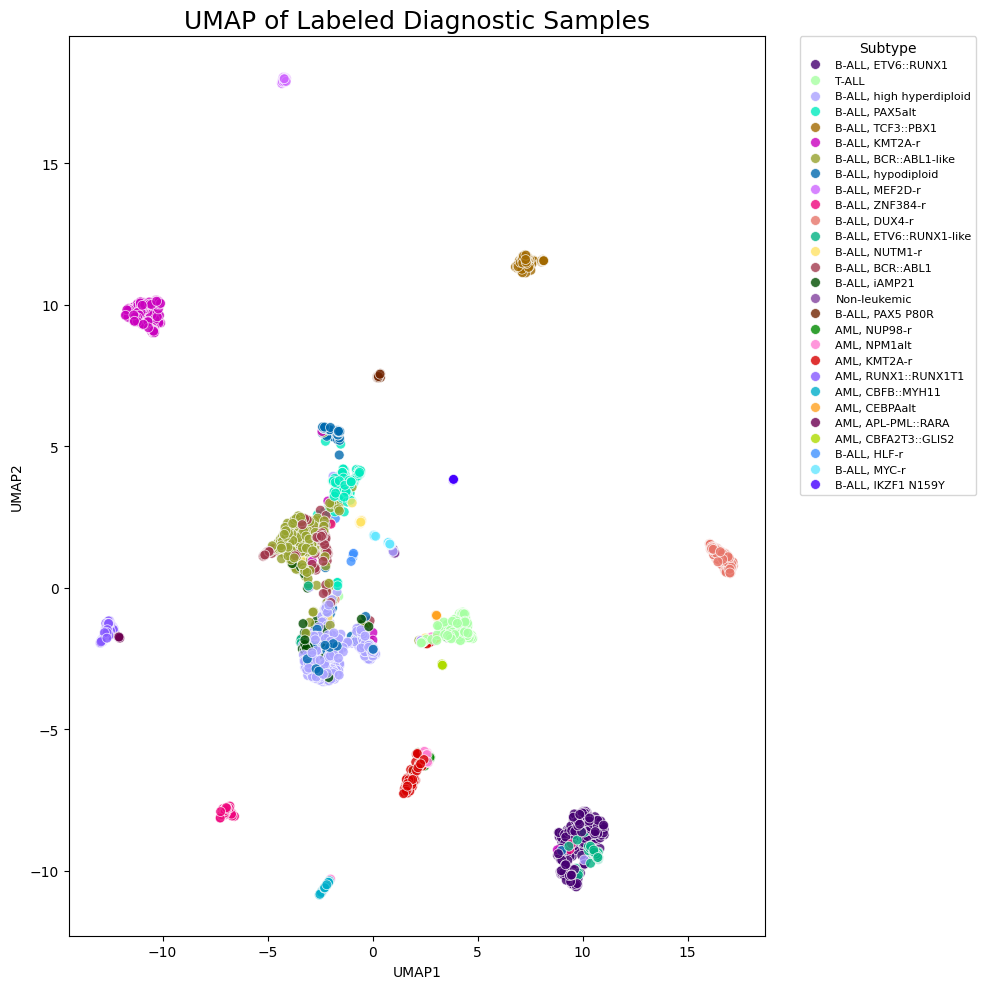

In [163]:
show_umap(umap_df, title='UMAP of Labeled Diagnostic Samples', palette=color_palette, legend_title='Subtype')